# Paths and geometry

Path data built from commands and markers, combined with boolean operations and measured: length, tight
bounds, points along an outline and hit tests.

Run it as ``python 03_paths_and_geometry.py`` or open ``03_paths_and_geometry.ipynb`` to see each step.

In [1]:
import numpy as np

import svgwriter as svg
from svgwriter import builder

`PathBuilder` writes path data with chained commands. Relative quadratic curves make a wave,
and `svg.markers.arrow` gives it an arrow head at its end, sized in stroke widths.

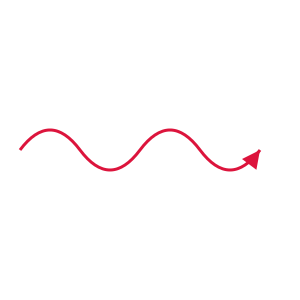

In [2]:
SIZE = 300
doc = svg.Document(SIZE, SIZE)
head = svg.markers.arrow(6, color="crimson")

wave = svg.PathBuilder().move_to(20, 150)
for _ in range(2):
    wave.quad_to(30, -40, 60, 0, relative=True).smooth_quad_to(60, 0, relative=True)
curve = doc.path(wave, fill="none", stroke="crimson", stroke_width=3, marker_end=head)
doc

Arcs: a pie slice from a line and an elliptical `arc_to`. `clone().rotate(...)` bakes a rotation
into a copy, giving the opposite slice.

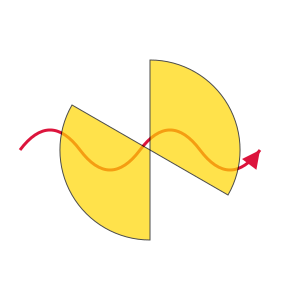

In [3]:
pie = svg.PathBuilder().move_to(150, 150).line_to(150, 60).arc_to(90, 90, 0, False, True, 228, 195).close()
slice_ = doc.path(pie, fill="gold", stroke="black", opacity=0.7)
doc += slice_.clone().rotate(180, about=(150, 150))
doc

`svgwriter.builder` has registered composite shapes (star, gear, arrow, dashed line) that return
ordinary shapes, here added together to one group.

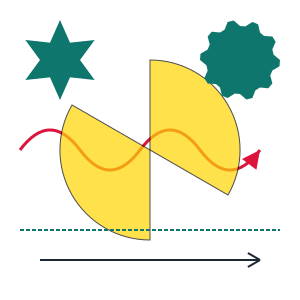

In [4]:
with doc.group(stroke="navy", fill="none") as outlines:
    outlines += [
        builder.star(60, 60, 40, points=6),
        builder.gear(240, 60, 40, teeth=10),
        builder.arrow(40, 260, 260, 260, head=14),
        builder.dashed_line(20, 230, 280, 230),
    ]
doc

## Measuring

Measure outlines: `total_length()` is the length along the curve, `exact_bbox()` the tight box
and `point_at_length(d)` the point `d` units along it. Dots every fifth of the wave show it, drawn
on a copy of the drawing (`root.clone()`) so the drawing above stays as it is.

wave length 298.8, tight box BBox(x=20.0, y=130.0, width=240.0, height=40.0)


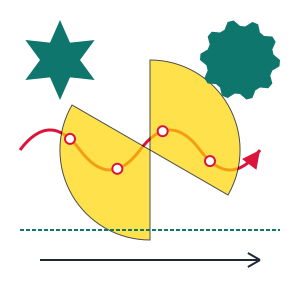

In [5]:
probe = svg.Document(root=doc.root.clone())
length = curve.total_length()
print(f"wave length {length:.1f}, tight box {curve.exact_bbox()}")
for step in range(1, 5):
    spot = curve.point_at_length(length * step / 5)
    probe.circle(spot.x, spot.y, 5, fill="white", stroke="crimson", stroke_width=2)
probe

`contains_point` tests points against the filled outline. It takes one point or an `(n, 2)` array and
returns one boolean each. Random points turn green inside the pie slice and grey outside.
Simple shapes also report `area` and `bbox` directly.

23 of 60 points inside; circle area 314.2


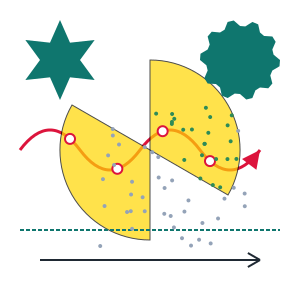

In [6]:
rng = np.random.default_rng(3)
points = rng.uniform(100, 250, size=(60, 2))
inside = slice_.contains_point(points)
print(f"{inside.sum()} of {len(points)} points inside; circle area {svg.Circle(0, 0, 10).area:.1f}")
for (x, y), hit in zip(points, inside, strict=True):
    probe.circle(x, y, 2, fill="seagreen" if hit else "#94a3b8")
probe

## Boolean operations

Boolean operations work on the outlines. `union` merges shapes into one path: six rotated ellipses
become a flower, and `-=` punches a hole in it.

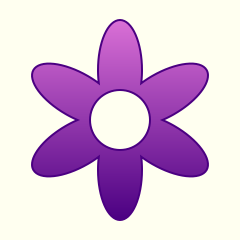

In [7]:
FLOWER = 240
CENTER = FLOWER / 2
PETALS = 6
FONT = "Arial, Helvetica, sans-serif"

flower_doc = svg.Document(FLOWER, FLOWER)
paint = svg.LinearGradient.vertical("orchid", "indigo")
flower_doc.rect(0, 0, FLOWER, FLOWER, fill="ivory")

petal = svg.Ellipse(CENTER, CENTER - 50, 22, 50)
petals = [petal.clone().rotate(360 * i / PETALS, about=(CENTER, CENTER)) for i in range(PETALS)]
blossom = petals[0].union(*petals[1:])
blossom -= svg.Circle(CENTER, CENTER, 30)
flower_doc.path(blossom.d, fill=paint, stroke="indigo", stroke_width=2)
flower_doc

Text takes part too: subtracting a letter from a disc leaves a badge with the letter cut out.

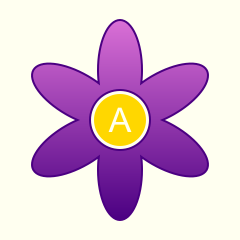

In [8]:
badge = svg.Circle(CENTER, CENTER, 26, fill="gold") - svg.Text("A", x=CENTER, y=CENTER + 12, font_size=34, font_family=FONT, text_anchor="middle")
flower_doc += badge
flower_doc

`stroked(width)` turns a stroke into a filled outline, here a ring around everything.

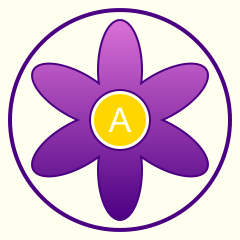

In [9]:
ring = svg.Circle(CENTER, CENTER, 110).stroked(4)
ring.set("fill", "indigo")
flower_doc += ring
flower_doc

Save a readable file and a compact one (shorter path data, fewer digits), and the flower.

In [10]:
doc.save("03_paths_pretty.svg")
probe.save("03_measure.svg")
doc.save("03_paths_compact.svg", pretty=False, compact_paths=True, precision=2)
flower_doc.save("03_boolean.svg")